In [1]:
import pandas as pd

In [2]:
df_reviews = pd.read_csv('IMDB Dataset.csv')

In [3]:
df_reviews

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


In [4]:
df_positive = df_reviews[df_reviews['sentiment'] == 'positive'][:9000]
df_negative = df_reviews[df_reviews['sentiment'] == 'negative'][:1000]

In [5]:
df_review_imb = pd.concat([df_positive,df_negative])

In [6]:
df_review_imb

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
5,"Probably my all-time favorite movie, a story o...",positive
...,...,...
2000,Stranded in Space (1972) MST3K version - a ver...,negative
2005,"I happened to catch this supposed ""horror"" fli...",negative
2007,waste of 1h45 this nasty little film is one to...,negative
2010,Warning: This could spoil your movie. Watch it...,negative


In [7]:
df_review_imb.value_counts('sentiment')

sentiment
positive    9000
negative    1000
Name: count, dtype: int64

<Axes: xlabel='sentiment'>

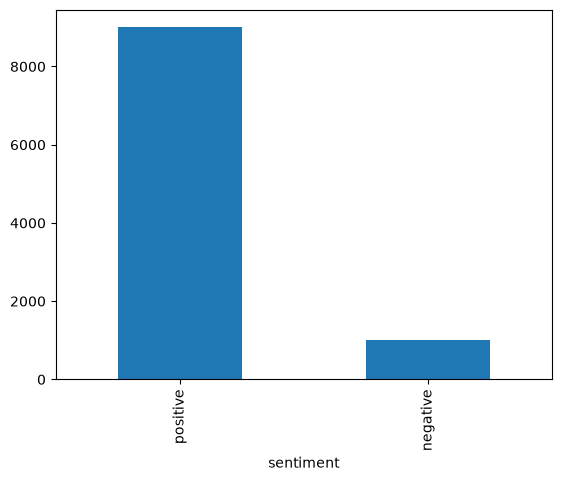

In [8]:
df_review_imb.value_counts('sentiment').plot(kind = 'bar')

balancing data with.sample()

In [10]:
length_negative = len(df_review_imb[df_review_imb['sentiment'] == 'negative'])

In [11]:
length_negative

1000

In [13]:
df_review_positive = df_review_imb[df_review_imb['sentiment'] == 'positive'].sample(n = length_negative )

In [14]:
df_review_negative = df_review_imb[df_review_imb['sentiment'] == 'negative']

In [17]:
df_review_bal = pd.concat([df_review_positive,df_review_negative])

In [19]:
df_review_bal.reset_index(drop = True, inplace = True)

In [21]:
df_review_bal.value_counts('sentiment')

sentiment
positive    1000
negative    1000
Name: count, dtype: int64

balancing data with random under sample

In [22]:
!pip install imblearn

In [23]:
from imblearn.under_sampling import RandomUnderSampler

In [24]:
rus = RandomUnderSampler(random_state = 0)

In [26]:
df_review_bal, df_review_bal['sentiment'] = rus.fit_resample(df_review_imb[['review']],df_review_imb['sentiment'])

In [27]:
df_review_bal

,review,sentiment
3,Basically there's a family where a little boy ...,negative
7,"This show was an amazing, fresh & innovative i...",negative
8,Encouraged by the positive comments about this...,negative
10,Phil the Alien is one of those quirky films wh...,negative
11,I saw this movie when I was about 12 when it c...,negative
...,...,...
10833,Knute Rockne led an extraordinary life and his...,positive
1039,At the height of the 'Celebrity Big Brother' r...,positive
5255,This is another of Robert Altman's underrated ...,positive
12237,This movie won a special award at Cannes for i...,positive


In [28]:
df_review_bal.value_counts('sentiment')

sentiment
negative    1000
positive    1000
Name: count, dtype: int64

over sampling

In [30]:
from imblearn.over_sampling import RandomOverSampler
rus = RandomOverSampler(random_state = 0)
df_review_bal, df_review_bal['sentiment'] = rus.fit_resample(df_review_imb[['review']],df_review_imb['sentiment'])

In [31]:
df_review_bal

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,"Petter Mattei's ""Love in the Time of Money"" is...",positive
4,"Probably my all-time favorite movie, a story o...",positive
...,...,...
17995,"Minimal script, minimal character development,...",negative
17996,What are Forest Whitaker and Clifton Collins J...,negative
17997,You cannot deny that we have an affinity for s...,negative
17998,. . . and that is only if you like the sight o...,negative


In [32]:
df_review_bal.value_counts('sentiment')

sentiment
positive    9000
negative    9000
Name: count, dtype: int64

splitting data into train and test data

In [35]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(df_review_bal, test_size = 0.33 , random_state = 42)

In [36]:
train

,review,sentiment
8962,I've watched many short films in my day. Often...,positive
4520,Farewell Friend aka Adieu L'Ami/Honour Among T...,positive
14957,"Of all the films I have seen, this one, The Ra...",negative
2992,"In the hands of a more skilled director, this ...",positive
10498,"If you came here, it's because you've already ...",negative
...,...,...
11284,Most Lorne Michaels films seem to fail because...,negative
11964,Filmfour are going to have to do a lot better ...,negative
5390,The Thing has to be one of the all time great ...,positive
860,It's unbelievable but the fourth is better tha...,positive


In [37]:
test

,review,sentiment
2574,During the Civil war a wounded union soldier h...,positive
7496,"""Cooley High"" is one of my favorite movies EVE...",positive
9210,I am so disappointed. This movie left me feeli...,negative
5456,I'm surprised with the amount of negative revi...,positive
736,This film revolves around an Arabian leader (A...,positive
...,...,...
6181,This is obviously aimed at the same market as ...,positive
12697,This was by far the worst movie I've ever seen...,negative
4526,"Until I saw this film, ""life is beautiful"" was...",positive
15529,This must have been one of the worst movies I ...,negative


In [38]:
train_x,train_y = train['review'],train['sentiment']

In [39]:
test_x,test_y = test['review'],test['sentiment']